# PINNs for Mechanical Engineers — Tutorial 6: The Backward-Facing Step
### Flow that lets go of the wall: separation, reattachment, and a bubble the network has to find

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems mechanical engineers actually deal with — fluids, heat, solids, and the messy places where they couple. Tutorial 5 was a held breath: one clean equation. This one goes back to the deep end. A fluid flows over a sudden drop in the floor, **separates** from the wall, swirls in a recirculation bubble, and **reattaches** downstream — and the PINN has to discover that bubble on its own, from nothing but the equations.


| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | ✅ |
| **6** | **Backward-Facing Step** | **flow separation & reattachment** | **📍 You are here** |
| 7 | Transient Heat Conduction | time-dependent PDEs, time-windowing | ✅ |
| 8 | The Inverse Problem | recovering physics from sparse data | ✅ |
| 9 | The Parametric PINN | one network, a family of solutions | ✅ |
| 10 | Multi-Material Heat Conduction | two domains, one interface | ✅ |

Every tutorial is standalone and validated against a reference solution. This problem has **no closed form**, so the reference is experimental: the classic **Armaly et al. (1983)** measurements, whose reattachment-length data every backward-facing-step solver is measured against.

> **New to PINNs?** This series assumes you're comfortable with the fundamentals: autograd, collocation points, the residual loss, the Adam → L-BFGS recipe. If you're starting from zero — or want the build-it-from-scratch treatment in one place — the 100+ page ebook covers all of it, from your first autograd call through 1D ODEs, Poisson, and Burgers.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---


## 1 — What You Will Learn

By the end of this tutorial you will be able to:

- reuse the same $(x,y)\rightarrow(u,v,p)$ PINN structure from Tutorial 1;
- build an L-shaped backward-facing-step domain;
- impose a fully developed parabolic inlet;
- impose no-slip on the four solid wall segments;
- use a zero-gradient outflow plus one pressure-gauge point;
- concentrate collocation points where separation actually occurs;
- add a **mass-flow loss** that stabilizes an open-flow PINN;
- train with the same **Adam → L-BFGS** sequence used in Tutorial 1;
- detect reverse flow and calculate the reattachment length;
- compare the PINN against the published Armaly benchmark;
- reject a visually attractive solution if it fails mass conservation or recirculation checks.

**Prerequisites:** the PINN fundamentals, and Tutorial 1 in particular — this is the same steady Navier–Stokes machinery (two momentum residuals, continuity, the pressure gauge) you built for the lid-driven cavity. What's new is the **geometry and the boundary conditions**: an open flow with an inlet and an outlet instead of a closed box, and a step that forces the flow to separate. If the Navier–Stokes fundamentals feel shaky, revisit Tutorial 1, or the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) for the foundations.

---

## 2 — The problem and its reference

We solve the steady incompressible Navier–Stokes equations in non-dimensional form. The reference length is the **step height** $s$, the reference velocity is the mean inlet velocity $\bar U$, and pressure is scaled by $\rho\bar U^2$:

$$
\begin{aligned}
u u_x + v u_y &= -p_x + \nu (u_{xx}+u_{yy}),\\
u v_x + v v_y &= -p_y + \nu (v_{xx}+v_{yy}),\\
u_x + v_y &= 0.
\end{aligned}
$$

The geometry follows the classical backward-facing-step experiment of Armaly et al.

We non-dimensionalize length by the **step height** $S$ and velocity by the mean inlet velocity $U_m$.

The published experiment used

$$
\begin{aligned}
Re_D=\frac{U_m D_h}{\nu},
\qquad D_h=2h_{\rm in}.
\end{aligned}
$$

For this tutorial:

$$
Re_D=100,
$$

which is safely inside the laminar, two-dimensional regime.

The experimental geometry had an expansion ratio of approximately $1:1.94$. With $S=1$,

$$
h_{\rm in}=\frac{0.52}{0.49},
\qquad
H=S+h_{\rm in}.
$$

The flow enters from the left, separates at the sharp step, forms a recirculation bubble along the lower wall, and eventually reattaches.

---


## 3 — Imports and setup

The style stays deliberately close to the earlier tutorials: imports, one seed, one device selection, and all of the main constants in one visible cell. On a CUDA machine the notebook automatically selects the full training settings; on CPU it selects a short code-check run.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {device}")
if device.type == "cuda":
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: CUDA is not visible to this kernel.")
    print("The notebook will still run, but the full training below will be slow on CPU.")

# Geometry: lengths are non-dimensionalized by step height S
S = 1.0
h_in = 0.52 / 0.49
H = S + h_in
L_IN = 4.0
L_OUT = 15.0

# Armaly Reynolds number: Re_D = U_mean * D_h / nu
RE = 100.0
D_H = 2.0 * h_in
NU = D_H / RE

print(f"h_in / S       : {h_in:.6f}")
print(f"H / S          : {H:.6f}")
print(f"D_h / S        : {D_H:.6f}")
print(f"Re_D            : {RE:.1f}")
print(f"nu              : {NU:.6f}")

# IMPORTANT:
# There is deliberately NO automatic '5-epoch CPU demo' in this notebook.
# The training numbers below are the real tutorial settings.

PyTorch version : 2.11.0+cu128
Device          : cuda
GPU             : Tesla T4
h_in / S       : 1.061224
H / S          : 2.061224
D_h / S        : 2.122449
Re_D            : 100.0
nu              : 0.021224


---

## 4 — The reference: Armaly et al. (1983)

The benchmark is:

**B. F. Armaly, F. Durst, J. C. F. Pereira & B. Schönung (1983)**  
*Experimental and theoretical investigation of backward-facing step flow*,  
Journal of Fluid Mechanics, 127, 473–496.  
DOI: **10.1017/S0022112083002839**

Important details for this notebook:

- expansion ratio $\approx 1:1.94$;
- inlet flow is nearly fully developed and parabolic in the laminar range;
- Reynolds number is based on the inlet hydraulic diameter;
- the flow is two-dimensional at the low Reynolds number used here;
- the primary recirculation bubble is measured through its reattachment location.

A later published comparison table reports the Armaly experimental value at $Re=100$ as approximately

$$
\frac{x_r}{S}=3.08,
$$

with a representative numerical value around $2.92$.

We will **not put $x_r$ into the training loss**. It is reserved for validation.

In [2]:
XR_ARMALY = 3.08
XR_NUMERICAL = 2.92

def inlet_velocity(y):
    """Fully developed parabolic inlet profile with mean velocity = 1."""
    eta = (y - S) / h_in
    return 6.0 * eta * (1.0 - eta)

y_ref = torch.linspace(S, H, 1001, device=device).view(-1, 1)
u_ref = inlet_velocity(y_ref)

Q_IN = torch.trapz(u_ref[:, 0], y_ref[:, 0]).item()

print(f"inlet u at lower wall : {u_ref[0].item():.6f}")
print(f"inlet u at upper wall : {u_ref[-1].item():.6f}")
print(f"inlet maximum         : {u_ref.max().item():.6f}  (expected 1.5)")
print(f"inlet flow rate       : {Q_IN:.6f}  (expected h_in = {h_in:.6f})")
print(f"Armaly x_r / S        : {XR_ARMALY:.2f}")
print(f"reference numerical   : {XR_NUMERICAL:.2f}")

inlet u at lower wall : 0.000000
inlet u at upper wall : 0.000000
inlet maximum         : 1.500000  (expected 1.5)
inlet flow rate       : 1.061224  (expected h_in = 1.061224)
Armaly x_r / S        : 3.08
reference numerical   : 2.92


**What just happened?** Before asking the neural network to solve anything, we checked the non-dimensionalization.

This is one of the important corrections relative to the earlier notebook. `RE = 100` now means the same Reynolds number used in the Armaly benchmark: mean inlet velocity times **inlet hydraulic diameter**, divided by kinematic viscosity.

That makes the comparison of reattachment length meaningful.

---

## 5 — Collocation points and the five kinds of boundary

In [3]:
# Interior collocation points
N_interior = 5000

N_pre    = 700
N_post   = 1100
N_bubble = 1900
N_shear  = N_interior - N_pre - N_post - N_bubble

def rand_between(a, b, n):
    return a + (b-a) * torch.rand(n, 1, device=device)

# upstream channel
x1 = rand_between(-L_IN, 0.0, N_pre)
y1 = rand_between(S, H, N_pre)

# downstream global region
x2 = rand_between(0.0, L_OUT, N_post)
y2 = rand_between(0.0, H, N_post)

# primary bubble region: concentrated near lower wall
x3 = rand_between(0.0, 5.5, N_bubble)
y3 = 0.85 * torch.rand(N_bubble, 1, device=device)**2

# separated shear layer from step corner
x4 = rand_between(0.0, 7.0, N_shear)
y4 = S + 0.55 * (2.0*torch.rand(N_shear,1,device=device)-1.0)
y4 = torch.clamp(y4, 0.02, H-0.02)

x_int = torch.cat([x1, x2, x3, x4], dim=0).requires_grad_(True)
y_int = torch.cat([y1, y2, y3, y4], dim=0).requires_grad_(True)

# Boundary points
N_inlet = 250
N_outlet = 250
N_wall = 220

# inlet
x_in = -L_IN * torch.ones(N_inlet, 1, device=device)
y_in = rand_between(S, H, N_inlet)
u_in = inlet_velocity(y_in)
v_in = torch.zeros_like(y_in)

# outlet
x_out = (L_OUT * torch.ones(N_outlet, 1, device=device)).requires_grad_(True)
y_out = rand_between(0.0, H, N_outlet).requires_grad_(True)

# no-slip walls
x_top = rand_between(-L_IN, L_OUT, N_wall)
y_top = H * torch.ones_like(x_top)

x_pre_floor = rand_between(-L_IN, 0.0, N_wall)
y_pre_floor = S * torch.ones_like(x_pre_floor)

x_step = torch.zeros(N_wall, 1, device=device)
y_step = rand_between(0.0, S, N_wall)

x_post_floor = rand_between(0.0, L_OUT, N_wall)
y_post_floor = torch.zeros_like(x_post_floor)

x_wall = torch.cat([x_top, x_pre_floor, x_step, x_post_floor], dim=0)
y_wall = torch.cat([y_top, y_pre_floor, y_step, y_post_floor], dim=0)

# Pressure gauge: one point only
x_p0 = torch.tensor([[L_OUT]], dtype=torch.float32, device=device)
y_p0 = torch.tensor([[H/2]], dtype=torch.float32, device=device)

# Flux stations: integral mass conservation
N_flux_y = 81
flux_stations = [1.0, 3.0, 6.0, 10.0, 14.0]
y_flux_one = torch.linspace(0.0, H, N_flux_y, device=device).view(-1,1)
x_flux = torch.cat([xs*torch.ones_like(y_flux_one) for xs in flux_stations], dim=0)
y_flux = torch.cat([y_flux_one.clone() for _ in flux_stations], dim=0)

print(f"interior : {x_int.shape[0]}")
print(f"inlet    : {x_in.shape[0]}")
print(f"outlet   : {x_out.shape[0]}")
print(f"walls    : {x_wall.shape[0]}")
print(f"gauge    : 1")
print(f"flux     : {len(flux_stations)} stations x {N_flux_y} points")

interior : 5000
inlet    : 250
outlet   : 250
walls    : 880
gauge    : 1
flux     : 5 stations x 81 points


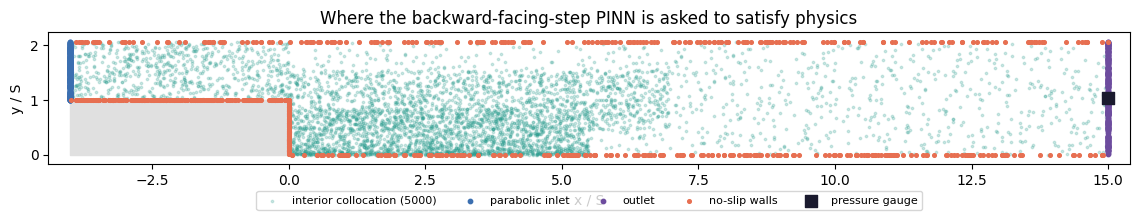

In [4]:
plt.figure(figsize=(11.5, 4.6))

plt.scatter(x_int.detach().cpu(), y_int.detach().cpu(),
            s=3, alpha=0.22, color="#2A9D8F",
            label=f"interior collocation ({N_interior})")

plt.scatter(x_in.detach().cpu(), y_in.detach().cpu(),
            s=10, color="#3B6FB0", label="parabolic inlet")

plt.scatter(x_out.detach().cpu(), y_out.detach().cpu(),
            s=10, color="#6D4C9E", label="outlet")

plt.scatter(x_wall.detach().cpu(), y_wall.detach().cpu(),
            s=7, color="#E76F51", label="no-slip walls")

plt.scatter([L_OUT], [H/2], s=65, marker="s", color="#1A1A2E",
            zorder=5, label="pressure gauge")

plt.fill_between([-L_IN, 0], 0, S, color="0.88", zorder=-1)

plt.xlim(-L_IN-0.4, L_OUT+0.4)
plt.ylim(-0.18, H+0.18)
plt.xlabel("x / S")
plt.ylabel("y / S")
plt.title("Where the backward-facing-step PINN is asked to satisfy physics")
plt.legend(loc="upper center", bbox_to_anchor=(0.5,-0.16), ncol=5, fontsize=8)
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()

**What just happened?** The point cloud is deliberately non-uniform.

A uniform cloud wastes most of its points in the easy, nearly parallel part of the channel. Here the densest region is exactly where the PINN must discover separation:

- just downstream of the step;
- close to the lower wall;
- around the free shear layer starting from the re-entrant corner.

This is still a physics-only collocation set. No measured velocity values have been added.

___

## 6 — The network: three coupled outputs

In [5]:
class PINN(nn.Module):
    """Input (x, y) -> output (u, v, p)."""
    def __init__(self, n_hidden=64, n_layers=5):
        super().__init__()

        layers = [nn.Linear(2, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 3)]

        self.net = nn.Sequential(*layers)

        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, y):
        x_hat = 2.0 * (x + L_IN) / (L_OUT + L_IN) - 1.0
        y_hat = 2.0 * y / H - 1.0

        out = self.net(torch.cat([x_hat, y_hat], dim=1))
        return out[:, 0:1], out[:, 1:2], out[:, 2:3]

model = PINN().to(device)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=64, bias=True)
    (9): Tanh()
    (10): Linear(in_features=64, out_features=3, bias=True)
  )
)
Trainable parameters: 17027


**What just happened?** This is intentionally almost the same network as Tutorial 1.

The only practical addition is coordinate scaling inside `forward()`. A cavity lives in $0\le x,y\le1$; this channel extends from $x=-4$ to $x=15$. Without scaling, `tanh` neurons can saturate and the open-flow problem becomes much harder to optimize.

The outputs are still exactly the same:

$$
(x,y)\longrightarrow(u,v,p).
$$

---

## 7 — The Navier–Stokes residuals

In [6]:
def grads(out, x, y):
    """d(out)/dx and d(out)/dy in ONE backward pass."""
    gx, gy = torch.autograd.grad(
        out, [x, y],
        grad_outputs=torch.ones_like(out),
        create_graph=True
    )
    return gx, gy


def ns_residuals(model, x, y, nu=NU):
    u, v, p = model(x, y)

    u_x, u_y = grads(u, x, y)
    v_x, v_y = grads(v, x, y)
    p_x, p_y = grads(p, x, y)

    u_xx, _ = grads(u_x, x, y)
    _, u_yy = grads(u_y, x, y)

    v_xx, _ = grads(v_x, x, y)
    _, v_yy = grads(v_y, x, y)

    r_x = u*u_x + v*u_y + p_x - nu*(u_xx + u_yy)
    r_y = u*v_x + v*v_y + p_y - nu*(v_xx + v_yy)
    r_c = u_x + v_y

    return r_x, r_y, r_c

print("NS residuals defined ✓  (same derivative structure as Tutorial 1)")

NS residuals defined ✓  (same derivative structure as Tutorial 1)


**Count the cost.** The derivative structure is the same as Tutorial 1: first derivatives of $u$, $v$, and $p$, followed by the second derivatives needed by viscosity.

Nothing special is inserted into the equations to create a vortex. The recirculation must emerge from Navier–Stokes, the sudden expansion, no-slip walls, and the imposed inlet flow.

---

## 8 — The loss: local physics + boundary conditions + global mass flow

In [7]:
lambda_inlet = 10.0
lambda_wall  = 20.0
lambda_flux  = 5.0
lambda_out   = 1.0
lambda_p0    = 1.0

Q_TARGET = h_in


def compute_loss(model):
    # 1) Navier-Stokes in the fluid
    r_x, r_y, r_c = ns_residuals(model, x_int, y_int)

    loss_mom = torch.mean(r_x**2) + torch.mean(r_y**2)
    loss_div = torch.mean(r_c**2)

    # 2) Inlet
    u_p, v_p, _ = model(x_in, y_in)
    loss_in = torch.mean((u_p-u_in)**2) + torch.mean((v_p-v_in)**2)

    # 3) Solid walls
    u_w, v_w, _ = model(x_wall, y_wall)
    loss_wall = torch.mean(u_w**2) + torch.mean(v_w**2)

    # 4) Outlet: zero streamwise velocity gradients
    u_o, v_o, _ = model(x_out, y_out)
    u_xo, _ = grads(u_o, x_out, y_out)
    v_xo, _ = grads(v_o, x_out, y_out)
    loss_out = torch.mean(u_xo**2) + torch.mean(v_xo**2)

    # 5) Pressure gauge
    _, _, p0 = model(x_p0, y_p0)
    loss_p0 = torch.mean(p0**2)

    # 6) Global mass-flow conservation
    u_f, _, _ = model(x_flux, y_flux)
    u_f = u_f.view(len(flux_stations), N_flux_y)

    q = torch.trapz(u_f, y_flux_one[:,0], dim=1)
    loss_flux = torch.mean((q-Q_TARGET)**2)

    total = (
        loss_mom + loss_div
        + lambda_inlet*loss_in
        + lambda_wall*loss_wall
        + lambda_flux*loss_flux
        + lambda_out*loss_out
        + lambda_p0*loss_p0
    )

    return (
        total,
        loss_mom.item(),
        loss_div.item(),
        loss_in.item(),
        loss_wall.item(),
        loss_out.item(),
        loss_flux.item()
    )


print("Loss defined ✓")

Loss defined ✓


---

## 9 — Training phase 1: Adam

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Real tutorial training settings.
n_epochs = 20000

history = {
    "epoch": [],
    "total": [],
    "mom": [],
    "div": [],
    "inlet": [],
    "wall": [],
    "out": [],
    "flux": [],
    "phase": []
}

t0 = time.time()

for epoch in range(1, n_epochs + 1):
    optimizer.zero_grad()

    total, l_mom, l_div, l_in, l_wall, l_out, l_flux = compute_loss(model)

    total.backward()
    optimizer.step()

    if epoch % 1000 == 0 or epoch == 1:
        history["epoch"].append(epoch)
        history["total"].append(total.item())
        history["mom"].append(l_mom)
        history["div"].append(l_div)
        history["inlet"].append(l_in)
        history["wall"].append(l_wall)
        history["out"].append(l_out)
        history["flux"].append(l_flux)
        history["phase"].append("Adam")

        print(
            f"Epoch {epoch:6d} | total {total.item():.3e} "
            f"| mom {l_mom:.3e} | div {l_div:.3e} "
            f"| inlet {l_in:.3e} | wall {l_wall:.3e} "
            f"| flux {l_flux:.3e}"
        )

print(f"Adam phase finished in {(time.time()-t0)/60:.1f} min")

Epoch      1 | total 1.649e+01 | mom 7.734e-02 | div 6.917e-03 | inlet 9.338e-01 | wall 5.880e-02 | flux 1.174e+00
Epoch   1000 | total 2.094e-02 | mom 1.344e-02 | div 1.018e-03 | inlet 1.062e-04 | wall 1.683e-04 | flux 3.763e-04
Epoch   2000 | total 1.584e-02 | mom 9.267e-03 | div 1.012e-03 | inlet 7.658e-05 | wall 1.900e-04 | flux 1.731e-04
Epoch   3000 | total 1.324e-02 | mom 7.802e-03 | div 9.880e-04 | inlet 4.995e-05 | wall 1.596e-04 | flux 1.269e-04
Epoch   4000 | total 1.057e-02 | mom 6.447e-03 | div 9.545e-04 | inlet 2.406e-05 | wall 1.309e-04 | flux 3.576e-05
Epoch   5000 | total 2.115e-02 | mom 5.370e-03 | div 1.320e-03 | inlet 2.686e-04 | wall 5.758e-04 | flux 3.311e-05
Epoch   6000 | total 5.751e-03 | mom 3.297e-03 | div 8.072e-04 | inlet 8.876e-06 | wall 7.244e-05 | flux 6.793e-06
Epoch   7000 | total 4.637e-03 | mom 2.605e-03 | div 7.179e-04 | inlet 1.021e-05 | wall 5.565e-05 | flux 8.813e-06
Epoch   8000 | total 4.588e-03 | mom 2.062e-03 | div 7.240e-04 | inlet 5.181e-05

**What just happened?** This is deliberately the same visible training loop as Tutorial 1.

There is no hidden Reynolds-number continuation loop and no automatic five-iteration demo.

Adam first finds the broad solution. For a backward-facing step, do not judge the model after Adam only. The reattachment location depends on a small near-wall derivative, and L-BFGS is especially useful for sharpening it.

---

## 10 — Training phase 2: L-BFGS

In [9]:
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=200,
    tolerance_grad=1e-9,
    tolerance_change=1e-11,
    history_size=50,
    line_search_fn="strong_wolfe"
)


def closure():
    optimizer_lbfgs.zero_grad()
    total, _, _, _, _, _, _ = compute_loss(model)
    total.backward()
    return total


t0 = time.time()

for rnd in range(1, 11):
    optimizer_lbfgs.step(closure)

    total, l_mom, l_div, l_in, l_wall, l_out, l_flux = compute_loss(model)

    history["epoch"].append(n_epochs + rnd*200)
    history["total"].append(total.item())
    history["mom"].append(l_mom)
    history["div"].append(l_div)
    history["inlet"].append(l_in)
    history["wall"].append(l_wall)
    history["out"].append(l_out)
    history["flux"].append(l_flux)
    history["phase"].append("L-BFGS")

    print(
        f"L-BFGS round {rnd:2d} | total {total.item():.3e} "
        f"| mom {l_mom:.3e} | div {l_div:.3e} "
        f"| inlet {l_in:.3e} | wall {l_wall:.3e} "
        f"| flux {l_flux:.3e}"
    )

print(f"L-BFGS phase finished in {(time.time()-t0)/60:.1f} min")

L-BFGS round  1 | total 1.367e-03 | mom 7.330e-04 | div 2.631e-04 | inlet 5.224e-07 | wall 1.775e-05 | flux 8.902e-07
L-BFGS round  2 | total 1.246e-03 | mom 6.633e-04 | div 2.488e-04 | inlet 1.598e-07 | wall 1.619e-05 | flux 1.005e-06
L-BFGS round  3 | total 1.127e-03 | mom 5.882e-04 | div 2.413e-04 | inlet 3.205e-07 | wall 1.448e-05 | flux 5.674e-07
L-BFGS round  4 | total 9.730e-04 | mom 4.986e-04 | div 1.924e-04 | inlet 1.342e-07 | wall 1.390e-05 | flux 2.001e-07
L-BFGS round  5 | total 8.137e-04 | mom 4.350e-04 | div 1.669e-04 | inlet 2.213e-07 | wall 1.035e-05 | flux 1.945e-07
L-BFGS round  6 | total 6.907e-04 | mom 3.673e-04 | div 1.444e-04 | inlet 2.100e-07 | wall 8.739e-06 | flux 1.414e-08
L-BFGS round  7 | total 6.190e-04 | mom 3.294e-04 | div 1.203e-04 | inlet 2.997e-07 | wall 8.147e-06 | flux 6.813e-08
L-BFGS round  8 | total 5.570e-04 | mom 2.840e-04 | div 1.227e-04 | inlet 4.093e-07 | wall 7.144e-06 | flux 1.353e-07
L-BFGS round  9 | total 4.990e-04 | mom 2.609e-04 | div 

**What just happened?** L-BFGS sees the complete collocation set every time the closure is evaluated.

Notice that the `history` dictionary is updated **after** `optimizer_lbfgs.step(closure)`, just like Tutorial 1. This keeps line-search evaluations out of the visible training record.

---

## 11 — The loss history, both phases

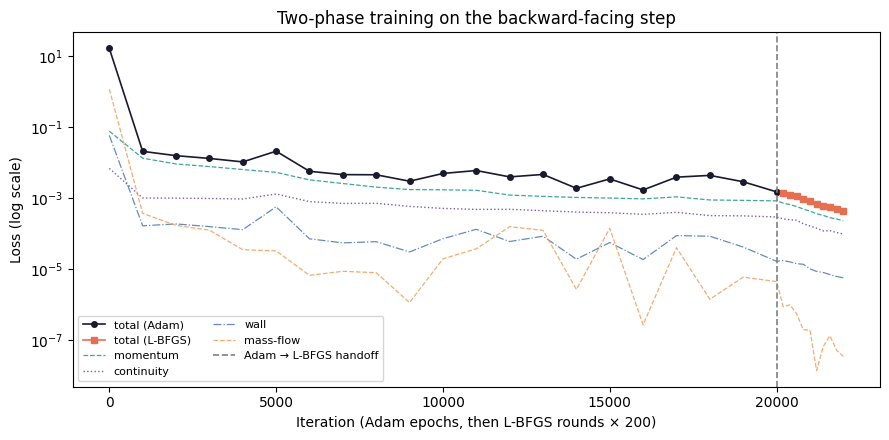

In [ ]:
ep = np.array(history["epoch"])
tot = np.array(history["total"])
mom = np.array(history["mom"])
div = np.array(history["div"])
lwall = np.array(history["wall"])
lflux = np.array(history["flux"])
ph = np.array(history["phase"])

am = ph == "Adam"
lm = ph == "L-BFGS"

plt.figure(figsize=(9, 4.5))

plt.semilogy(ep[am], tot[am], "o-", color="#1A1A2E",
             ms=4, lw=1.2, label="total (Adam)")

plt.semilogy(ep[lm], tot[lm], "s-", color="#E76F51",
             ms=4, lw=1.2, label="total (L-BFGS)")

plt.semilogy(ep, mom, "--", color="#2A9D8F",
             lw=0.9, alpha=0.9, label="momentum")

plt.semilogy(ep, np.maximum(div,1e-14), ":", color="#6D4C9E",
             lw=1.0, alpha=0.9, label="continuity")

plt.semilogy(ep, np.maximum(lwall,1e-14), "-.", color="#3B6FB0",
             lw=0.9, alpha=0.8, label="wall")

plt.semilogy(ep, np.maximum(lflux,1e-14), "--", color="#F4A261",
             lw=0.9, alpha=0.9, label="mass-flow")

plt.axvline(n_epochs, color="gray", ls="--", lw=1.2,
            label="Adam → L-BFGS handoff")

plt.xlabel("Iteration (Adam epochs, then L-BFGS rounds × 200)")
plt.ylabel("Loss (log scale)")
plt.title("Two-phase training on the backward-facing step")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

The shape should look familiar from Tutorial 1: a long Adam descent followed by smaller but important L-BFGS improvements.

For this problem, pay special attention to the **wall** and **mass-flow** curves. A low total loss is not enough if those terms remain large.

---

## 12 — The flow field: did we get a recirculation bubble?

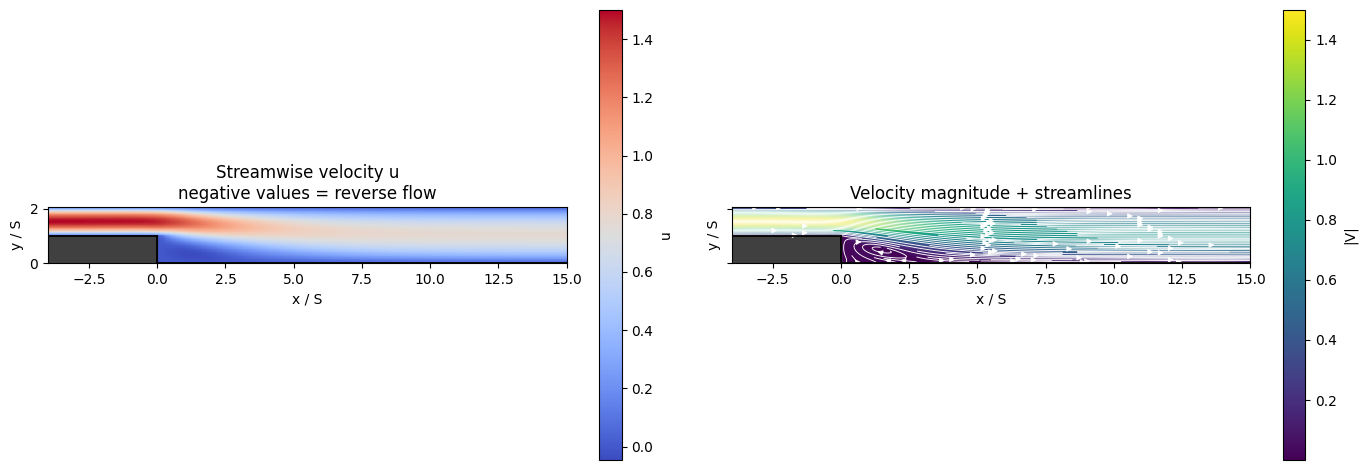

In [11]:
nx, ny = 420, 130

xg = np.linspace(-L_IN, L_OUT, nx)
yg = np.linspace(0.0, H, ny)
X, Y = np.meshgrid(xg, yg)

MASK = ((X >= 0.0) & (Y >= 0.0) & (Y <= H)) | \
       ((X < 0.0) & (Y >= S) & (Y <= H))

pts_x = torch.tensor(X[MASK], dtype=torch.float32, device=device).view(-1,1)
pts_y = torch.tensor(Y[MASK], dtype=torch.float32, device=device).view(-1,1)

with torch.no_grad():
    ug, vg, pg = model(pts_x, pts_y)

U = np.full_like(X, np.nan, dtype=float)
V = np.full_like(X, np.nan, dtype=float)
P = np.full_like(X, np.nan, dtype=float)

U[MASK] = ug.cpu().numpy().ravel()
V[MASK] = vg.cpu().numpy().ravel()
P[MASK] = pg.cpu().numpy().ravel()

SPEED = np.sqrt(U**2 + V**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)

im0 = axes[0].pcolormesh(X, Y, U, cmap="coolwarm", shading="auto")
plt.colorbar(im0, ax=axes[0], label="u")
axes[0].set_title("Streamwise velocity u\nnegative values = reverse flow")

im1 = axes[1].pcolormesh(X, Y, SPEED, cmap="viridis", shading="auto")
plt.colorbar(im1, ax=axes[1], label="|V|")

Um = np.ma.masked_invalid(U)
Vm = np.ma.masked_invalid(V)

axes[1].streamplot(
    xg, yg, Um, Vm,
    density=1.7,
    color="white",
    linewidth=0.65,
    arrowsize=0.8
)
axes[1].set_title("Velocity magnitude + streamlines")

for ax in axes:
    ax.fill_between([-L_IN,0], 0, S, color="0.25")
    ax.plot([-L_IN,L_OUT],[H,H],"k-",lw=1.3)
    ax.plot([-L_IN,0],[S,S],"k-",lw=1.3)
    ax.plot([0,0],[0,S],"k-",lw=1.3)
    ax.plot([0,L_OUT],[0,0],"k-",lw=1.3)
    ax.set_xlabel("x / S")
    ax.set_ylabel("y / S")
    ax.set_xlim(-L_IN, L_OUT)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

**What should you see?**

Immediately behind the step, the lower part of the $u$ contour should become **negative**. The streamlines should curl into a closed primary recirculation zone and then join the downstream flow again.

If every streamline moves monotonically downstream, the PINN has **not** converged to the backward-facing-step solution.

---

## 13 — The moment of truth: reattachment length vs. the published benchmark

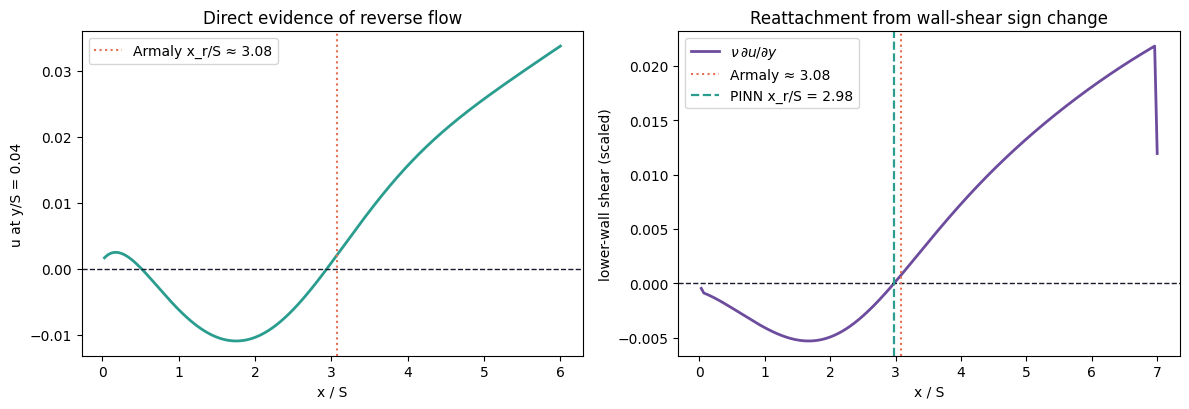

In [12]:
def wall_shear_profile(n=900):
    x = torch.linspace(0.03, 7.0, n, device=device).view(-1,1)
    y = torch.zeros_like(x)

    x.requires_grad_(True)
    y.requires_grad_(True)

    u, _, _ = model(x, y)
    _, u_y = grads(u, x, y)

    tau = (NU*u_y).detach().cpu().numpy().ravel()
    xx = x.detach().cpu().numpy().ravel()

    return xx, tau


def reattachment_from_wall_shear():
    x, tau = wall_shear_profile()

    kernel = np.ones(11) / 11
    tau_s = np.convolve(tau, kernel, mode="same")

    idx = np.where(
        (x[:-1] > 0.20) &
        (tau_s[:-1] < 0.0) &
        (tau_s[1:] >= 0.0)
    )[0]

    if len(idx) == 0:
        return np.nan, x, tau_s

    i = idx[0]

    xr = x[i] - tau_s[i]*(x[i+1]-x[i]) / \
         (tau_s[i+1]-tau_s[i] + 1e-14)

    return float(xr), x, tau_s


@torch.no_grad()
def near_wall_profile(y_probe=0.04, n=500):
    x = torch.linspace(0.03, 6.0, n, device=device).view(-1,1)
    y = y_probe * torch.ones_like(x)
    u, _, _ = model(x, y)
    return x.cpu().numpy().ravel(), u.cpu().numpy().ravel()


xr, x_tau, tau = reattachment_from_wall_shear()
x_probe, u_probe = near_wall_profile()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(x_probe, u_probe, color="#2A9D8F", lw=2)
axes[0].axhline(0, color="#1A1A2E", ls="--", lw=1)
axes[0].axvline(XR_ARMALY, color="#E76F51", ls=":", lw=1.5,
                label=f"Armaly x_r/S ≈ {XR_ARMALY:.2f}")
axes[0].set_xlabel("x / S")
axes[0].set_ylabel("u at y/S = 0.04")
axes[0].set_title("Direct evidence of reverse flow")
axes[0].legend()

axes[1].plot(x_tau, tau, color="#6D4C9E", lw=2,
             label=r"$\nu\,\partial u/\partial y$")
axes[1].axhline(0, color="#1A1A2E", ls="--", lw=1)
axes[1].axvline(XR_ARMALY, color="#E76F51", ls=":", lw=1.5,
                label=f"Armaly ≈ {XR_ARMALY:.2f}")

if np.isfinite(xr):
    axes[1].axvline(xr, color="#2A9D8F", ls="--", lw=1.6,
                    label=f"PINN x_r/S = {xr:.2f}")

axes[1].set_xlabel("x / S")
axes[1].set_ylabel("lower-wall shear (scaled)")
axes[1].set_title("Reattachment from wall-shear sign change")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
u_min = float(np.min(u_probe))

print(f"minimum near-wall u        : {u_min:+.5f}")

if np.isfinite(xr):
    abs_err = abs(xr - XR_ARMALY)
    pct_err = 100.0 * abs_err / XR_ARMALY

    print(f"PINN reattachment x_r / S : {xr:.4f}")
    print(f"Armaly experiment          : {XR_ARMALY:.4f}")
    print(f"representative numerical   : {XR_NUMERICAL:.4f}")
    print(f"absolute error vs Armaly   : {abs_err:.4f}")
    print(f"percentage error           : {pct_err:.2f} %")
else:
    print("No negative-to-positive wall-shear crossing was detected.")
    print("The model is not yet a converged backward-facing-step solution.")

minimum near-wall u        : -0.01091
PINN reattachment x_r / S : 2.9772
Armaly experiment          : 3.0800
representative numerical   : 2.9200
absolute error vs Armaly   : 0.1028
percentage error           : 3.34 %


**Read this like a CFD engineer.**

There are two separate questions:

1. **Did separation occur?**  
   The near-wall $u$ profile must become negative.

2. **Did the separated flow reattach at the right place?**  
   The wall shear should cross from negative back to positive near the published $x_r/S$ value.

A pretty streamline plot is not sufficient evidence.

---

## 14 — Where the physics is hardest: the re-entrant corner

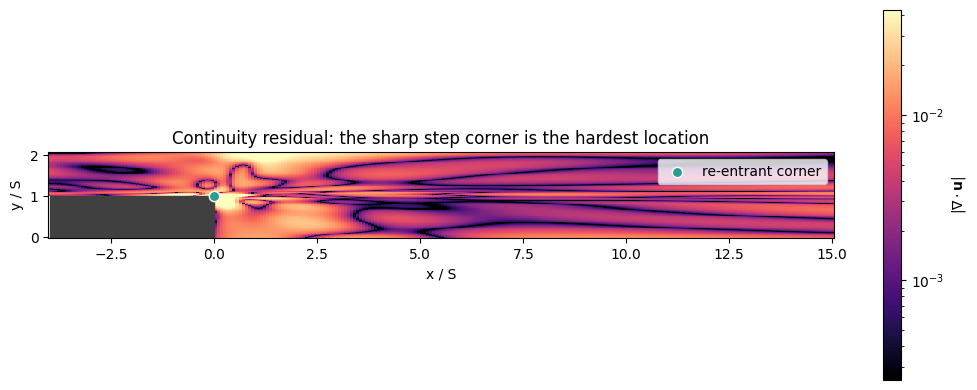

mean |div u| : 5.9182e-03
max  |div u| : 5.5664e-01


In [14]:
xv = np.linspace(-L_IN, L_OUT, 260)
yv = np.linspace(0.0, H, 100)
XX, YY = np.meshgrid(xv, yv)

mask = ((XX >= 0.0) & (YY >= 0.0) & (YY <= H)) | \
       ((XX < 0.0) & (YY >= S) & (YY <= H))

xf = torch.tensor(XX[mask], dtype=torch.float32, device=device).view(-1,1)
yf = torch.tensor(YY[mask], dtype=torch.float32, device=device).view(-1,1)

xf.requires_grad_(True)
yf.requires_grad_(True)

uf, vf, _ = model(xf, yf)
u_x, _ = grads(uf, xf, yf)
_, v_y = grads(vf, xf, yf)

div = (u_x + v_y).detach().cpu().numpy().ravel()

DIV = np.full_like(XX, np.nan, dtype=float)
DIV[mask] = np.abs(div)

plt.figure(figsize=(10.5, 4.0))

positive = DIV[np.isfinite(DIV) & (DIV > 0)]
vmin = max(1e-6, np.percentile(positive, 5)) if len(positive) else 1e-6
vmax = max(vmin*10, np.percentile(positive, 99)) if len(positive) else 1.0

im = plt.pcolormesh(
    XX, YY, DIV,
    cmap="magma",
    norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
    shading="auto"
)

plt.colorbar(im, label=r"$|\nabla\cdot \mathbf{u}|$")
plt.fill_between([-L_IN,0], 0, S, color="0.25")
plt.scatter([0],[S],s=55,color="#2A9D8F",edgecolor="white",zorder=5,
            label="re-entrant corner")

plt.xlabel("x / S")
plt.ylabel("y / S")
plt.title("Continuity residual: the sharp step corner is the hardest location")
plt.legend()
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()

print(f"mean |div u| : {np.nanmean(DIV):.4e}")
print(f"max  |div u| : {np.nanmax(DIV):.4e}")

**What just happened?** A sharp backward-facing step contains a geometric singularity.

Just as the moving-lid corners were the hardest points in Tutorial 1, the re-entrant corner is usually the worst local region here.

The important question is whether the residual is small over the rest of the fluid and whether the integral quantities are correct.

---

## 15 — The convergence gate: do not trust the result until it passes

In [15]:
@torch.no_grad()
def mass_flow_at(x0, n=401):
    y0 = S if x0 < 0 else 0.0

    yy = torch.linspace(y0, H, n, device=device).view(-1,1)
    xx = x0 * torch.ones_like(yy)

    u, _, _ = model(xx, yy)
    return torch.trapz(u[:,0], yy[:,0]).item()


with torch.no_grad():
    ui, vi, _ = model(x_in, y_in)
    uw, vw, _ = model(x_wall, y_wall)

inlet_rms = torch.sqrt(torch.mean((ui-u_in)**2)).item()
wall_speed_max = torch.sqrt(uw**2 + vw**2).max().item()

stations = [-L_IN, 1.0, 3.0, 6.0, 10.0, 14.0]
flows = [mass_flow_at(x0) for x0 in stations]
max_flux_error = max(abs(q-Q_TARGET) for q in flows)

print("Independent checks")
print("------------------")
print(f"inlet u RMS error       : {inlet_rms:.4e}")
print(f"maximum wall speed      : {wall_speed_max:.4e}")

for x0, q in zip(stations, flows):
    print(f"Q(x={x0:5.1f})              : {q:.6f}   error={q-Q_TARGET:+.3e}")

print(f"minimum near-wall u     : {u_min:+.5f}")
print(f"reattachment x_r/S      : {xr if np.isfinite(xr) else np.nan:.4f}")

has_reverse_flow = u_min < -5e-3
reattachment_ok = np.isfinite(xr) and (2.5 < xr < 3.7)
flux_ok = max_flux_error < 0.05 * Q_TARGET
wall_ok = wall_speed_max < 0.08

print()
if has_reverse_flow and reattachment_ok and flux_ok and wall_ok:
    print("PASS ✓")
    print("The PINN has the expected recirculation and is consistent with the benchmark.")
else:
    print("NOT YET CONVERGED")
    print("Do not use the contour as a final result.")

    if not has_reverse_flow:
        print(" - reverse flow is too weak or absent")
    if not reattachment_ok:
        print(" - reattachment location is missing or outside the expected range")
    if not flux_ok:
        print(" - downstream mass-flow error is too large")
    if not wall_ok:
        print(" - no-slip wall error is too large")

    print()
    print("Recommended action: continue Adam at lr=2e-4 for 2000-4000 epochs,")
    print("then run 3-5 additional L-BFGS rounds.")

Independent checks
------------------
inlet u RMS error       : 2.7188e-04
maximum wall speed      : 2.5946e-02
Q(x= -4.0)              : 1.061210   error=-1.433e-05
Q(x=  1.0)              : 1.061060   error=-1.644e-04
Q(x=  3.0)              : 1.061463   error=+2.386e-04
Q(x=  6.0)              : 1.061411   error=+1.861e-04
Q(x= 10.0)              : 1.061419   error=+1.940e-04
Q(x= 14.0)              : 1.061210   error=-1.493e-05
minimum near-wall u     : -0.01091
reattachment x_r/S      : 2.9772

PASS ✓
The PINN has the expected recirculation and is consistent with the benchmark.


---

In [16]:
torch.save(
    {
        "model_state": model.state_dict(),
        "history": history,
        "Re_D": RE,
        "nu": NU,
        "geometry": {
            "S": S,
            "h_in": h_in,
            "H": H,
            "L_IN": L_IN,
            "L_OUT": L_OUT
        },
        "benchmark_xr_over_S": XR_ARMALY
    },
    "PME_Tutorial_06_BFS_PINN.pt"
)

print("Saved: PME_Tutorial_06_BFS_PINN.pt")

Saved: PME_Tutorial_06_BFS_PINN.pt


This gate is intentional.

The notebook explicitly asks:

- Is there negative $u$?
- Is there a reattachment point?
- Is it in the published range?
- Is the flow rate conserved?
- Is the wall approximately no-slip?

Only then should the field plots be treated as a solution.

---

## 16 — Exercises

1. **Reduce the interior points.** Change `N_interior` from 5000 to 2000. Does the reattachment point move?

2. **Remove the bubble-focused points.** Replace the four-region sampling with uniform sampling. Does the PINN still discover reverse flow?

3. **Remove `lambda_flux`.** Set `lambda_flux = 0`. Compare the downstream mass-flow history.

4. **Change Reynolds number.** Try $Re_D=70$, $150$, and $300$. Remember that `NU = D_H / RE`.

5. **Change the outlet length.** Try `L_OUT = 10` and `L_OUT = 20`.

6. **Network study.** Compare 4, 5, and 6 hidden layers.

7. **Reattachment definition.** Compare the wall-shear zero crossing with the zero crossing of $u(x,y/S=0.04)$.

---

## 17 — Common failure modes (backward-facing-step edition)

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Smooth field but no reversed flow** | direct high-Re training, weak wall loss, or too few points near the step | keep the Reynolds continuation; strengthen wall enforcement; add corner and near-wall points |
| **Mass flow changes strongly downstream** | continuity is underweighted relative to boundary terms | inspect the continuity RMS; increase interior points or separate the continuity weight |
| **Large velocities inside the solid notch** | plotting the rectangular bounding box without masking the solid region | apply the L-shaped `inside_fluid` mask before plotting |
| **Outlet controls the whole solution** | outlet too close to reattachment or outlet loss too strong | lengthen $L_o$; reduce `W_OUTLET`; compare profiles before and after the change |
| **Noisy wall-shear crossings** | the velocity field looks smooth but its derivative is less converged | train longer, increase near-wall sampling, and inspect the unsmoothed shear before accepting $x_r$ |
| **Pressure drifts by a constant** | no pressure gauge | keep $p=0$ at the outlet or fix pressure at one point |
| **NaN or out-of-memory during L-BFGS** | full-batch second derivatives and optimizer history are memory intensive | reduce `N_f`, reduce `LBFGS_ITERS`, lower `history_size`, or disable L-BFGS |
| **CUDA available but the run is still slow** | too many collocation points or unnecessary diagnostic calls | first use `FULL_TRAINING=False`; then scale one setting at a time |

---

## 18 — Vocabulary

- **Backward-facing step** — a sudden channel expansion produced by a drop in the wall.
- **Separation** — detachment of the near-wall flow from the solid boundary at the sharp corner.
- **Recirculation bubble** — the downstream region where the local streamwise velocity becomes negative.
- **Reattachment point** — the lower-wall location where the separated shear layer returns to the wall.
- **Reattachment length ($x_r$)** — distance from the step face to the primary reattachment point, usually scaled by step height.
- **Re-entrant corner** — the $270^\circ$ fluid-domain corner at the top of the step face.
- **Expansion ratio ($ER$)** — downstream channel height divided by upstream channel height.
- **Outflow boundary** — an outlet condition intended to let the solution leave without prescribing the full velocity profile.
- **Pressure gauge** — one pressure condition that removes the arbitrary additive constant in incompressible pressure.
- **Wall shear** — the tangential viscous stress at the wall; its sign change identifies reattachment.
- **Reynolds continuation** — training first at lower Reynolds numbers and progressively increasing to the target.
- **Laminar model** — the molecular-viscosity Navier–Stokes equations used directly, with no turbulence closure.

---

## 19 — What You Have Built (and Where the Series Goes)

The notebook now follows the same tutorial structure as the earlier files while solving the actual backward-facing-step problem throughout:

| Choice | What it bought |
|--------|---------------|
| step-height and mean-velocity scaling | every field and coordinate remains near order one |
| L-shaped collocation sampling | physics is enforced only in the fluid, with extra attention near separation |
| direct $(u,v,p)$ network | the formulation stays close to the standard incompressible equations |
| explicit inlet, wall, and outlet losses | every boundary family remains visible and debuggable |
| laminar Reynolds continuation | an easier route from viscous attached flow to a separated target solution |
| wall-shear post-processing | a physical scalar validation target, the reattachment length |

The important result is not a low total loss by itself. A credible solution must simultaneously show small independent residuals, no-slip walls, the correct inlet profile, nearly conserved mass flow, negative $u$ behind the step, and a stable wall-shear sign change.

**The honest engineering verdict:** for a single backward-facing-step geometry, a conventional laminar CFD solver is still the direct and reliable tool. The value of this notebook is that it exposes every part of a PINN solution — geometry sampling, nonlinear residuals, mixed boundaries, training balance, and physics-based validation — in one compact example.

**Where this series goes.** Tutorial 7 closes Part I by adding the one ingredient every tutorial so far has lacked — **time**. It does so on transient *heat conduction* rather than on unsteady flow, and that choice is deliberate: diffusion has an exact analytical solution, so every digit of the time machinery can be checked. It also introduces the problem that time creates for a PINN — a network optimizes all times at once and has no sense of causality — and the fix that restores it, time-windowed marching.

Then Part II flips the question entirely. Tutorial 8 hands you sparse noisy sensors and asks you to recover the *physics* rather than the field. Tutorial 9 trains one network across a whole family of operating conditions. Tutorial 10 closes with two materials joined at an interface.

**A note on this tutorial's discipline.** The convergence gate in Section 15 — reversed flow present, reattachment point found, in the published range, mass conserved — is the habit worth carrying forward. Tutorial 4 showed a loss falling smoothly toward zero while the fluid stood perfectly still. A small loss is not a solution, and this notebook is where the series makes that a checklist rather than a warning.

---

### Get the Notebooks

The full series — all ten tutorials, with plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

### References

- Armaly, B. F., Durst, F., Pereira, J. C. F. & Schönung, B. (1983). *Experimental and theoretical investigation of backward-facing step flow.* J. Fluid Mech. **127**, 473–496. — *the experimental benchmark: reattachment length versus Reynolds number, and the laminar/transitional/turbulent regime map.*
- Erturk, E. (2008). *Numerical solutions of 2-D steady incompressible flow over a backward-facing step.* Computers & Fluids **37**, 633–655. — *high-resolution numerical reattachment data.*
- Biswas, G., Breuer, M. & Durst, F. (2004). *Backward-facing step flows for various expansion ratios at low and moderate Reynolds numbers.* J. Fluids Eng. **126**, 362–374. — *expansion-ratio effects, relevant to the exercises.*

*Next up: time enters the picture — and a PINN discovers it has no sense of time's arrow. — Rohit Raj · HalfQubiX*